In [2]:
import numpy as np 
import matplotlib.pyplot as plt
np.random.seed(0) 

In [3]:
A_list = [] 
b_list = []
for i in range(1000):
    random_vector = np.random.normal(0, 1, 10)
    dim = 10
    mean = np.zeros(dim)
    A_list.append(random_vector)
    one_vector = np.ones(dim) 
    dot_products = np.dot(one_vector, random_vector) 
    signs = np.where(dot_products > 0, 1, -1) 
    b_list.append(signs) 
A = np.array(A_list) 
b = np.array(b_list) 

In [4]:
def clip_exp(z, threshold=709):
    """Clip values to prevent overflow in exp."""
    return np.clip(z, -threshold, threshold)

def stable_sigmoid(z):
    """Compute the sigmoid function in a numerically stable way using clipped exp."""
    z_clipped = clip_exp(z)  # Clip values before applying exp
    return 1 / (1 + np.exp(-z_clipped))

def f_value(A, b, x, lambda_=0.01):
    m = len(b)  # Number of training examples
    # Compute the logistic loss with overflow protection
    # Clip the input to exp to prevent overflow
    logits = -b * np.dot(A, x)
    log_loss = np.sum(np.log(1 + np.exp(clip_exp(logits)))) / m
    
    # Compute the regularization term
    reg_term = lambda_ * np.dot(x, x)
    
    return log_loss + reg_term

def f_gradient(A, b, x, lambda_=0.01):
    m = len(b)  # Number of training examples
    logits = np.dot(A, x)  # Linear combination
    h_theta = stable_sigmoid(logits)  # Predicted probabilities
    
    # Compute gradient
    gradient = -np.dot(A.T, (b - h_theta)) / m + 2 * lambda_ * x
    
    return gradient

def f_hessian(A, b, theta, lambda_=0.01):
    m = len(b)  # Number of training examples
    logits = np.dot(A, theta)  # Linear combination
    h_theta = stable_sigmoid(logits)  # Predicted probabilities
    
    # Compute diagonal matrix D
    D = np.diag(h_theta * (1 - h_theta))  # Diagonal elements h(theta)(1 - h(theta))
    
    # Compute Hessian: H = -A^T D A / m + 2 * lambda * I
    Hessian = -np.dot(A.T, np.dot(D, A)) / m + 2 * lambda_ * np.eye(A.shape[1])
    
    return Hessian

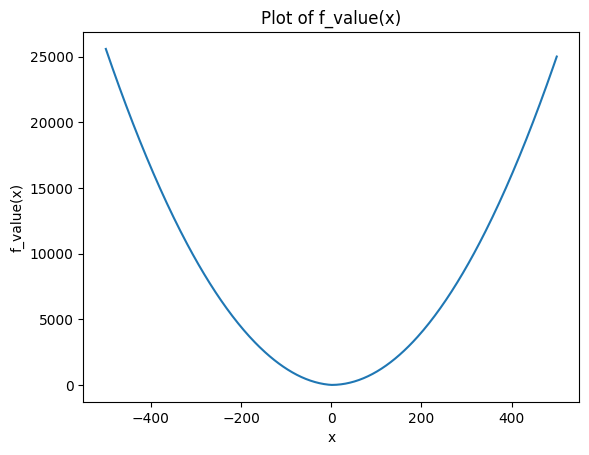

In [5]:
x_values = np.linspace(-500, 500, 400)
f_values = [f_value(A,b,np.full(10, x)) for x in x_values]

plt.plot(x_values, f_values)
plt.xlabel('x')
plt.ylabel('f_value(x)')
plt.title('Plot of f_value(x)')
plt.show()

Gradient Descent with learning rate 0.02: [np.float64(31.081051452289604), np.float64(11.565045762927788), np.float64(4.579121205149947), np.float64(2.0842421264946758), np.float64(1.1935688680218912), np.float64(0.8749147104070518), np.float64(0.760339880149965), np.float64(0.7187813128762677), np.float64(0.7034909964893593), np.float64(0.6977390412216782), np.float64(0.6955027123677019), np.float64(0.6945925195587536), np.float64(0.6941999552256974), np.float64(0.6940191722242303), np.float64(0.6939303032690416), np.float64(0.6938840429690992), np.float64(0.6938588567685622), np.float64(0.6938446958240782), np.float64(0.6938365599293229), np.float64(0.6938318203055093), np.float64(0.6938290352040918), np.float64(0.6938273899217985), np.float64(0.6938264148549402), np.float64(0.6938258358697591), np.float64(0.6938254916756912), np.float64(0.6938252869180811), np.float64(0.6938251650594205), np.float64(0.693825092518995), np.float64(0.6938250493305079), np.float64(0.6938250236150444), 

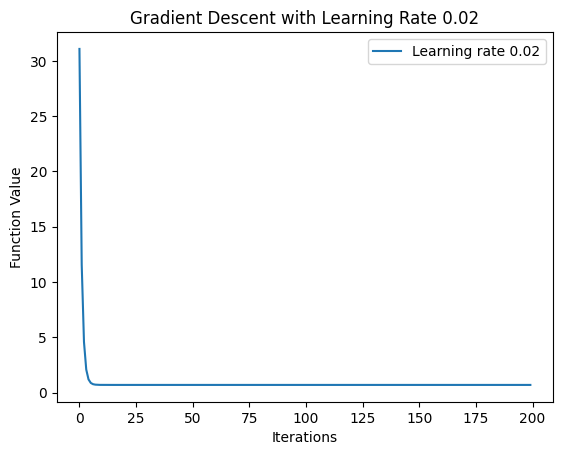

Gradient Descent with learning rate 0.2: [np.float64(769.3219820901052), np.float64(6950.324997603086), np.float64(62589.86019432016), np.float64(563560.1929805888), np.float64(5072317.010285663), np.float64(45653234.27144323), np.float64(410883665.32908016), np.float64(3697988893.1008515), np.float64(33281957629.5073), np.float64(299537965864.91016), np.float64(2695842230963.6357), np.float64(24262583228384.934), np.float64(218363253919244.34), np.float64(1965269313645738.8), np.float64(1.7687423866605922e+16), np.float64(1.5918681505483133e+17), np.float64(1.4326813358876508e+18), np.float64(1.289413202528728e+19), np.float64(1.160471882311331e+20), np.float64(1.0444246941008835e+21), np.float64(9.399822246939884e+21), np.float64(8.459840022264513e+22), np.float64(7.613856020040936e+23), np.float64(6.852470418038519e+24), np.float64(6.167223376234926e+25), np.float64(5.550501038611587e+26), np.float64(4.995450934750451e+27), np.float64(4.495905841275419e+28), np.float64(4.04631525714

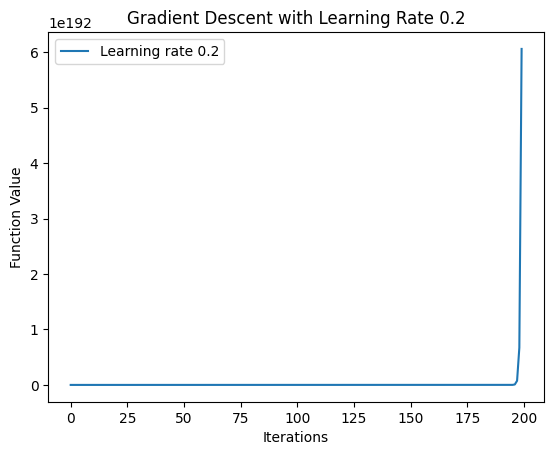

Gradient Descent with learning rate 2.0: [np.float64(129137.97531441547), np.float64(196434070.7153341), np.float64(298777561186.1172), np.float64(454440806404168.9), np.float64(6.912044692784492e+17), np.float64(1.0513219979800227e+21), np.float64(1.599060758931779e+24), np.float64(2.432171414335552e+27), np.float64(3.699332721204382e+30), np.float64(5.626685068951865e+33), np.float64(8.558187989875787e+36), np.float64(1.301700393260107e+40), np.float64(1.9798862981486232e+43), np.float64(3.011407059484056e+46), np.float64(4.5803501374752493e+49), np.float64(6.966712559099856e+52), np.float64(1.059636980239088e+56), np.float64(1.611707846943653e+59), np.float64(2.451407635201296e+62), np.float64(3.7285910131411718e+65), np.float64(5.671186930987722e+68), np.float64(8.625875322032324e+71), np.float64(1.3119956364811164e+75), np.float64(1.995545363087778e+78), np.float64(3.0352244972565103e+81), np.float64(4.616576460327152e+84), np.float64(7.0218127961575995e+87), np.float64(1.06801772

/tmp/ipykernel_11765/584625035.py:28: RuntimeWarning: overflow encountered in multiply
  gradient = -np.dot(A.T, (b - h_theta)) / m + 2 * lambda_ * x
/tmp/ipykernel_11765/4250374026.py:5: RuntimeWarning: overflow encountered in multiply
  vector = vector - learning_rate * f_gradient(A,b, vector, lambda_)


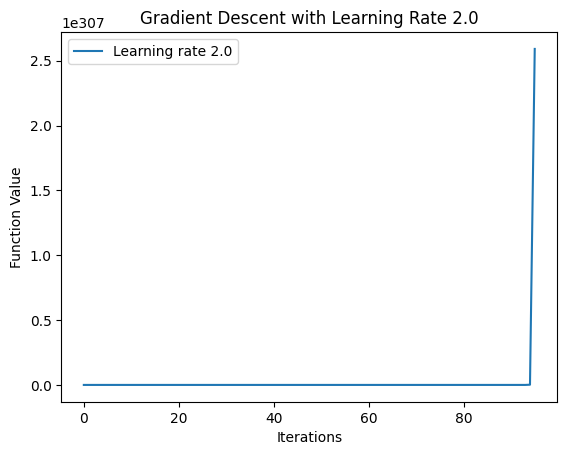

In [6]:
def grad_desc(x, learning_rate, lambda_):
    grad_desc = []
    vector = x
    for i in range(200):
        vector = vector - learning_rate * f_gradient(A,b, vector, lambda_)
        grad_desc.append(f_value(A,b,vector, lambda_))
    return grad_desc 

def main(init_vector,learning_rate,lambda_):
    # init_vector = np.array([10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0])
   
    grad = grad_desc(init_vector, learning_rate,lambda_)

    print("Gradient Descent with learning rate {}: {}".format(learning_rate, grad))
    
    plt.plot(grad, label='Learning rate {}'.format(learning_rate))
    plt.xlabel('Iterations')
    plt.ylabel('Function Value')
    plt.title('Gradient Descent with Learning Rate {}'.format(learning_rate))
    plt.legend()
    plt.savefig(f"Q5,lambda={lambda_},lr={learning_rate}.png")
    plt.show()

if __name__ == "__main__": 
    init_vector = np.random.normal(0, 1, 10)
    learning_rates = [0.02,0.2,2.0]
    lambda_ = 10.0
    for lr in learning_rates:
        main(init_vector,lr,lambda_)


Newton Method with learning rate 1: [np.float64(8.384000064863674), np.float64(407.9258414182303), np.float64(468.649), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(nan), np.float64(na

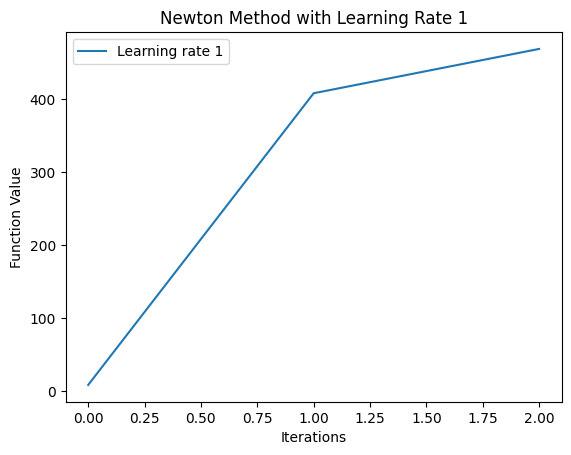

In [7]:
def newton_method(x, learning_rate, lambda_, tol=1e-6, max_iter=200):
    newton_steps = []
    vector = x
    for i in range(max_iter):
        grad = f_gradient(A, b, vector, lambda_)
        hess = f_hessian(A, b, vector, lambda_)
        hess_inv = np.linalg.inv(hess)
        vector = vector - learning_rate * np.dot(hess_inv, grad)
        newton_steps.append(f_value(A, b, vector, lambda_))
        if np.linalg.norm(grad) < tol:
            break
    return newton_steps

def main_newton(learning_rate,lambda_value):
    init_vector = np.random.normal(0, 1, 10)
    newton_steps = newton_method(init_vector, learning_rate,lambda_=lambda_value)

    print("Newton Method with learning rate {}: {}".format(learning_rate, newton_steps))
    
    plt.plot(newton_steps, label='Learning rate {}'.format(learning_rate))
    plt.xlabel('Iterations')
    plt.ylabel('Function Value')
    plt.title('Newton Method with Learning Rate {}'.format(learning_rate))
    plt.legend()
    plt.savefig(f"Q6,lambda={lambda_value},lr={learning_rate}.png")
    plt.show()

if __name__ == "__main__":
    learning_rate = 1
    lambda_value = 0.0
    main_newton(learning_rate,lambda_value)

Projected Gradient Descent with learning rate 0.02: [np.float64(0.7673319047917929), np.float64(0.7606706729842763), np.float64(0.754095300845361), np.float64(0.7476050731556807), np.float64(0.7411992621628576), np.float64(0.7348771282957706), np.float64(0.7286379208776724), np.float64(0.7224808788363174), np.float64(0.7164052314094057), np.float64(0.7104101988437876), np.float64(0.704494993087023), np.float64(0.6986588184700421), np.float64(0.6929008723798148), np.float64(0.6872203459210806), np.float64(0.6816164245663456), np.float64(0.6760882887934906), np.float64(0.6706351147104709), np.float64(0.665256074666702), np.float64(0.6599503378508396), np.float64(0.6547170708747516), np.float64(0.6495554383435596), np.float64(0.6444646034116859), np.float64(0.6394437283248968), np.float64(0.6344364303073189), np.float64(0.6294363279914519), np.float64(0.6245092983740458), np.float64(0.6196562952806218), np.float64(0.6148781703126084), np.float64(0.6101756742766503), np.float64(0.605549458

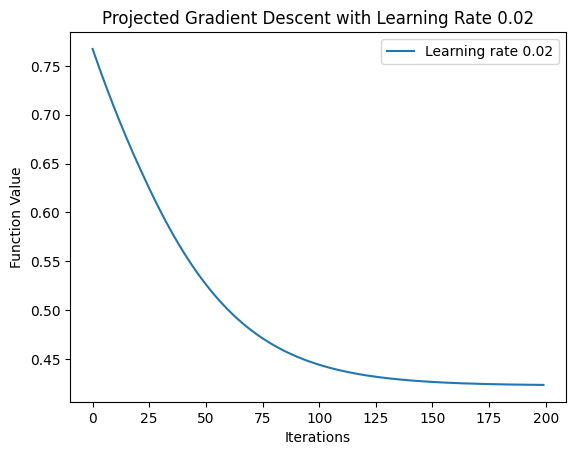

Projected Gradient Descent with learning rate 0.2: [np.float64(0.7542697184776901), np.float64(0.6919667121623305), np.float64(0.637439347041892), np.float64(0.5901365620932275), np.float64(0.5509376573942572), np.float64(0.5194438873348525), np.float64(0.49477182884773), np.float64(0.4758338980318203), np.float64(0.4615325237159484), np.float64(0.4508717903558581), np.float64(0.44300679301455165), np.float64(0.4372528420216737), np.float64(0.4330727101075005), np.float64(0.43005450445157883), np.float64(0.42788765930269906), np.float64(0.42634084773224695), np.float64(0.4252433112738387), np.float64(0.4244698553343891), np.float64(0.4239291742260657), np.float64(0.4235549611201152), np.float64(0.423299238378973), np.float64(0.42312740555778977), np.float64(0.42301458997672353), np.float64(0.42294297177221657), np.float64(0.4228998311243749), np.float64(0.4228761271117945), np.float64(0.42286546603761926), np.float64(0.42286335407109743), np.float64(0.422866656884121), np.float64(0.422

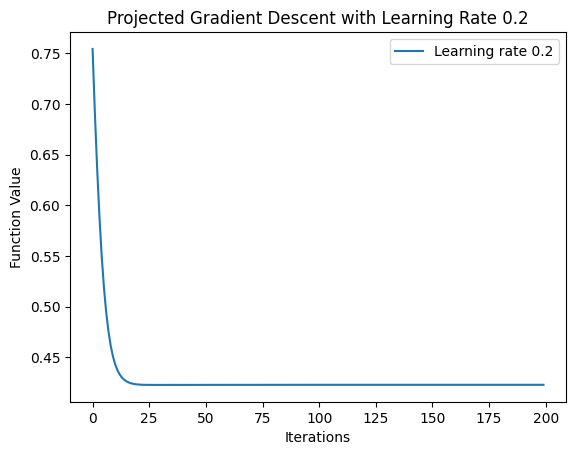

Projected Gradient Descent with learning rate 2.0: [np.float64(0.6143269233700198), np.float64(0.43251419066349783), np.float64(0.42308005681412614), np.float64(0.4228602789410631), np.float64(0.4229403642111865), np.float64(0.4229706558707038), np.float64(0.4229794024586262), np.float64(0.4229818020976473), np.float64(0.42298245177978294), np.float64(0.42298262687511373), np.float64(0.422982673960539), np.float64(0.4229826866046851), np.float64(0.4229826899966658), np.float64(0.42298269090591956), np.float64(0.4229826911495108), np.float64(0.4229826912147398), np.float64(0.4229826912322007), np.float64(0.42298269123687354), np.float64(0.4229826912381236), np.float64(0.4229826912384581), np.float64(0.42298269123854754), np.float64(0.4229826912385714), np.float64(0.4229826912385779), np.float64(0.4229826912385795), np.float64(0.42298269123858), np.float64(0.4229826912385801), np.float64(0.4229826912385802), np.float64(0.4229826912385802), np.float64(0.4229826912385802), np.float64(0.422

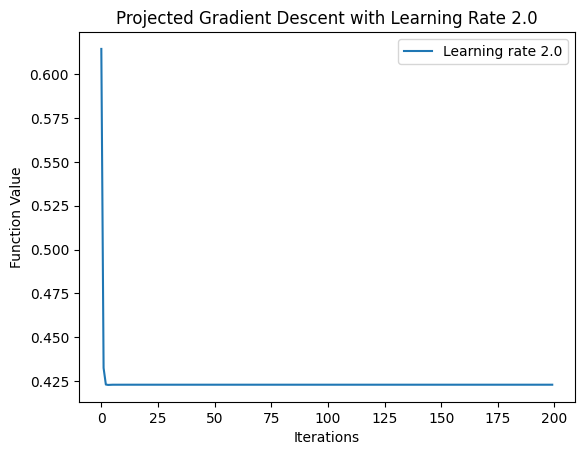

In [8]:
def project_onto_l2_ball(x, C):
    """Project the vector x onto the L2 ball of radius C."""
    norm = np.linalg.norm(x)
    if norm > C:
        return x * C / norm
    return x

def projected_grad_desc(x, learning_rate, lambda_, C, T=200):
    projected_grad_desc = []
    vector = x
    for i in range(T):
        vector = vector - learning_rate * f_gradient(A, b, vector, lambda_)
        vector = project_onto_l2_ball(vector, C)
        projected_grad_desc.append(f_value(A, b, vector, lambda_))
    return projected_grad_desc

def main_projected(init_vector, learning_rate, lambda_, C):
    projected_grad = projected_grad_desc(init_vector, learning_rate, lambda_, C)

    print("Projected Gradient Descent with learning rate {}: {}".format(learning_rate, projected_grad))
    
    plt.plot(projected_grad, label='Learning rate {}'.format(learning_rate))
    plt.xlabel('Iterations')
    plt.ylabel('Function Value')
    plt.title('Projected Gradient Descent with Learning Rate {}'.format(learning_rate))
    plt.legend()
    plt.savefig(f"Q7,lambda={lambda_},lr={learning_rate}.png")
    plt.show()

if __name__ == "__main__":
    init_vector = np.random.normal(0, 1, 10)
    learning_rates = [0.02, 0.2, 2.0]
    lambda_ = 0.01
    C = 1.0
    for lr in learning_rates:
        main_projected(init_vector, lr, lambda_, C)